In [1]:
import numpy as np # массивы
import k3d # визуализауия
import matplotlib.pyplot as plt # графики
from collections import deque # для хранения результатов симуляций
from pykdtree.kdtree import KDTree # библиотека с готовым алгоритмом поиска расстояний между точками в двух больших массивах

# Задача 1. Создание детектора

In [2]:
# Объявляем константы

vector3 = np.ndarray

cm = 1
m = 100*cm

golden_ratio_minus_1 = 2/(1+np.sqrt(5)) # Распределение фотоумножители сделано по спирали Фибоначчи, поэтому нам нужно вот такое число 

#### Как определить, попал ли фотон с координатами $(x_0, y_0, z_0) = \vec{r_0}$ и вектором направления $(n_x, n_y, n_z) = \vec{n}$ в ФЭУ?

Известно, что параметризация прямой при заданных $\vec{r_0}, \vec{n}$ выглядит как $\vec{r} = \vec{r_0}+\vec{n}t$
Необходимо найти t при котором $r^2=R$:

$x^2+y^2+z^2-R^2 = (x_0+n_xt)^2+(y_0+n_yt)^2+(z_0+z_xt)^2-R^2 = (n_x^2+n_y^2+n_z^2)t^2+2(x_0n_x+y_0n_y+z_0n_z)t-R^2+y_0^2+x_0^2+z_0^2=t^2+2(\vec{r_0}, \vec{n})t-R^2+r_0^2=0$

Решая квадратное уравнение, получаем:
$t=-(\vec{r_0}, \vec{n})+\sqrt{(\vec{r_0}, \vec{n})^2+R^2-r_0^2}$

Подставив, полученное t в параметризацию, найдём координаты пересечения траектории фотона со сферой. Далее можно применить функцию, определяющую принадлежит ли точка на поверхности ФЭУ

In [3]:
class Detector:

    def __init__(self, R : float, N : int, r : float, a : float): # При инициализации сразу создаём массив координат фотоумножителей
    
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        # Если расположить центр фотокатода на поверхности сферы, то остальная его часть будет за её пределами
        # Считаем, на какое расстояние нужно отступить, чтобы фотокатод был погружен внутрь сферы

        beta = (np.pi-np.asin(r/R))/2
        delta_h = r/np.tan(beta)
        R_photo = R-delta_h

        # Алгоритм по распределению дететкоров по сфере взят из https://arxiv.org/pdf/0912.4540

        N_points = (N-1)/2

        if (N_points % 1 == 0):

            indices = np.arange(-N_points, N_points+1)
            
        else:

            indices = np.arange(np.floor(-N_points), N_points)

        # Изначально задаются сферические углы (тета сдвинут на пи пополам, чтобы покрыть верхнюю и нижнюю полусферы)
        
        theta = np.asin(2*indices/N)+np.pi/2
        phi = 2*np.pi*indices*golden_ratio_minus_1

        # Задаётся массив декартовых координат фотокатодов

        self.photo_coords = R_photo*np.array([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)]).T

    # Функция по определнию того, сколько фотонов прилетело на каждый фотоумножитель
    def is_PMT(self, x : float=0, y : float=0, z : float=0, vector: vector3=None) -> np.ndarray: 
        
        if vector is None:
            vec = np.array([[x, y, z]])
        else:
            vec = np.array(vector)

        DetectorHits = np.zeros(self.N, dtype=int) # Массив количества фотонов, пойманных каждым ФЭУ. Изначально нудевой
        # distances = np.linalg.norm(vec, axis=-1)

        # Для определения принадлежности точки к ФЭУ используется k-d-дерево
        # Ниже можно найти самописный метод, но он медленней, т.к. нужно итерировать по каждой точке
        
        tree = KDTree(self.photo_coords)
        neighbor_dists, neighbor_indices = tree.query(vec) # получаем массив расстояний до ближайшего ФЭУ и массив индексов этих фЭУ
        
        filt = (neighbor_dists <= self.r) # отбираем только точки, лежащие ближе 10 см к ФЭУ
        good_inds = neighbor_indices[filt]

        for i in range(self.N):

            DetectorHits[i] = (good_inds == i).sum() # считаем, сколько раз каждый индекс встречается в массиве точек, близких к одному из ФЭУ

        # самописный метод, делающий то же самое
        
        # for i, point in enumerate(vec):
            
        #     PMT_distance = np.linalg.norm((self.photo_coords-point), axis=1)
        #     condition = (PMT_distance <= self.r)
        #     if np.any(condition):
                
        #         DetectorHits[condition.argmax()] += 1 

        return DetectorHits # i-ый элемент полученного массива равен числу фотонов, попавших на i-ый ФЭУ
    
    # Функция, определяет конечные точки траекторий фотонов. Суть метода изложена выше
    def GeneratePhotonEndPoints(self, source_coords : vector3, directions : vector3):
        
        source_coord_norm2 = np.linalg.norm(source_coords)**2
        scalar_product = (source_coords*directions).sum(axis=-1)
        Discr = scalar_product**2+self.R**2-source_coord_norm2
        roots = -scalar_product+np.sqrt(Discr)

        EndPoints = source_coords + directions*roots[:, np.newaxis]

        return EndPoints

    # Метод, возвращающий число фотоэлектронов отдельно на каждом из N ФЭУ
    # Настоящий метод принадлежит классу Detector, поскольку фотоэлектроны образуются внутри ФЭУ.
    
    def GetPoissoonCounts(self, hits):
        
        PhotoelectronNum = np.zeros(self.N)

        for i, n_hit in enumerate(hits):

            PhotoelectronNum[i] = np.random.poisson(self.a, size=n_hit).sum() # На каждом детекторе считается суммарное количество образованных фотоэлектронов

        return PhotoelectronNum
    

In [4]:
MyDet = Detector(2*m, 40, 10*cm, 0.5) # Объявляем дететкор с заданными параметрами

In [5]:
positions = MyDet.photo_coords # положения ФЭУ
positions.shape

(40, 3)

In [6]:
MyDet.is_PMT(vector=[[200,0,0], [0, 0, 200], [0,200,0]]) # Маленькая проверка на адекватность

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [7]:
colours = np.full(positions.shape[0], 0xff0000)

In [8]:
# Визуализация геометрии. Синий шар - сцинтиллятор. Красные шарики - ФЭУ

plot = k3d.plot()
plot += k3d.points([0,0,0], point_size=2*MyDet.R)
plot += k3d.points(positions, point_size=2*MyDet.r, colors=colours)

plot.display()

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\traittypes\traittypes.py:98: UserWarning: Given trait value dtype "int64" does not match required type "uint32". A coerced copy has been created.
  warnings.warn(


Output()

In [9]:
# Ещё немного полезных констант

keV = 1e-3
MeV = 1

In [10]:
class Source: # Источник фотонов

    def __init__(self, Y : int):
    
        self.Y = Y

    def GeneratePhotonDirections(self, E): # изтропный генератор направлений от события с энергией E

        N_photons = int(self.Y*E) # Считаем, сколько фотонов должно образоваться

        # Изотропно -> равномерно по косинусу тета и равномерно по фи
        cos_theta = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1-cos_theta**2)
        phi = np.random.uniform(0, 2*np.pi, N_photons)

        # Получаем единичные вектора направлений
        directions = np.array([sin_theta*np.cos(phi), sin_theta*np.sin(phi), cos_theta]).T
        
        return directions

In [11]:
MySource = Source(10000/MeV) # Объявляем источник

In [12]:
directions = MySource.GeneratePhotonDirections(1*MeV) # генерируем случайные направления от события 1 МэВ
directions

array([[-0.27860081,  0.78859127,  0.54818373],
       [ 0.16341405, -0.7433618 , -0.64862091],
       [-0.90192376,  0.4210668 ,  0.09610558],
       ...,
       [-0.5564754 , -0.74029452,  0.3772256 ],
       [-0.12377272,  0.15658727,  0.97987792],
       [-0.98095462,  0.18987296, -0.04094244]], shape=(10000, 3))

In [13]:
x0 = 0*cm
y0 = 0*cm
z0 = 0*cm

source_coordinates = np.array([x0, y0, z0]) # Положение источника в центре сферы

In [14]:
EndPoints = MyDet.GeneratePhotonEndPoints(source_coordinates, directions) # Пересечения траекторий со сферой
EndPoints

array([[ -55.72016204,  157.71825359,  109.63674579],
       [  32.68280976, -148.6723605 , -129.72418113],
       [-180.38475218,   84.21335907,   19.22111693],
       ...,
       [-111.29508066, -148.05890357,   75.44511975],
       [ -24.75454452,   31.31745437,  195.97558414],
       [-196.19092496,   37.97459203,   -8.18848718]], shape=(10000, 3))

In [15]:
Hits = MyDet.is_PMT(vector=EndPoints) # Количество фотонов на каждом ФЭУ
Hits

array([ 6,  4, 12,  6,  4,  8,  6,  8,  9,  6,  6,  5,  5, 10,  6,  4,  6,
        9,  4,  4,  3,  7,  9,  5,  4,  3, 11,  9, 12,  3,  8,  8,  2,  3,
        6,  8,  4,  6, 10, 10])

In [16]:
ChargeArray = MyDet.GetPoissoonCounts(Hits) # Количество фотоэлектронов на каждом ФЭУ
ChargeArray  

array([3., 1., 3., 4., 3., 3., 1., 2., 8., 3., 3., 3., 1., 5., 5., 3., 4.,
       3., 3., 0., 1., 6., 4., 0., 3., 1., 5., 4., 5., 1., 3., 3., 2., 2.,
       2., 4., 4., 1., 4., 8.])

In [17]:
ChargeArray.sum() # Суммарное количество фотоэлектронов

np.float64(124.0)

### Сравнение с ожиданиями

# $aY\frac{Nr^2}{4R^2} = 125$

В прицнипе, сходится :)

In [18]:
# Моделируем 1000 событий с заданными параметрами

E = 1*MeV

x0 = 0*cm
y0 = 0*cm
z0 = 0*cm

source_coordinates = np.array([x0, y0, z0])

In [19]:
Charges = deque()

In [20]:
for i in range(1000):

    directions = MySource.GeneratePhotonDirections(E)
    EndPoints = MyDet.GeneratePhotonEndPoints(source_coordinates, directions)
    Hits = MyDet.is_PMT(vector=EndPoints)
    Charge = (MyDet.GetPoissoonCounts(Hits)).sum()
    Charges.append(Charge)

Text(0, 0.5, 'Отсчёты')

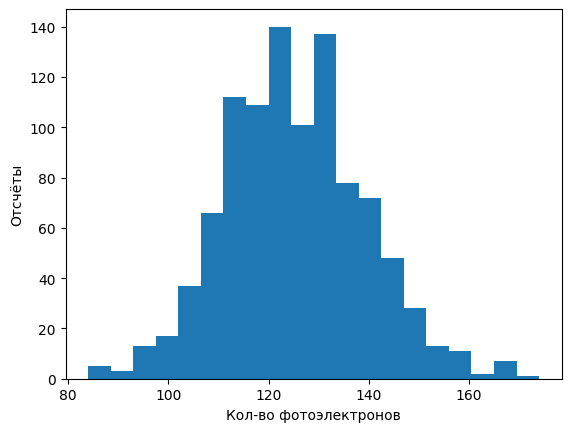

In [21]:
plt.hist(Charges, bins=20)

plt.xlabel('Кол-во фотоэлектронов')
plt.ylabel('Отсчёты')

In [22]:
# То же самое для набора энергий

Energies = [0.2*MeV, 0.5*MeV, 0.7*MeV, 1.5*MeV, 2.0*MeV, 3.0*MeV]

In [23]:
Charges = [deque() for i in range(len(Energies))]

In [24]:
for i, E in enumerate(Energies):
    for _ in range(1000):

        directions = MySource.GeneratePhotonDirections(E)
        EndPoints = MyDet.GeneratePhotonEndPoints(source_coordinates, directions)
        Hits = MyDet.is_PMT(vector=EndPoints)
        Charge = (MyDet.GetPoissoonCounts(Hits)).sum()
        Charges[i].append(Charge)

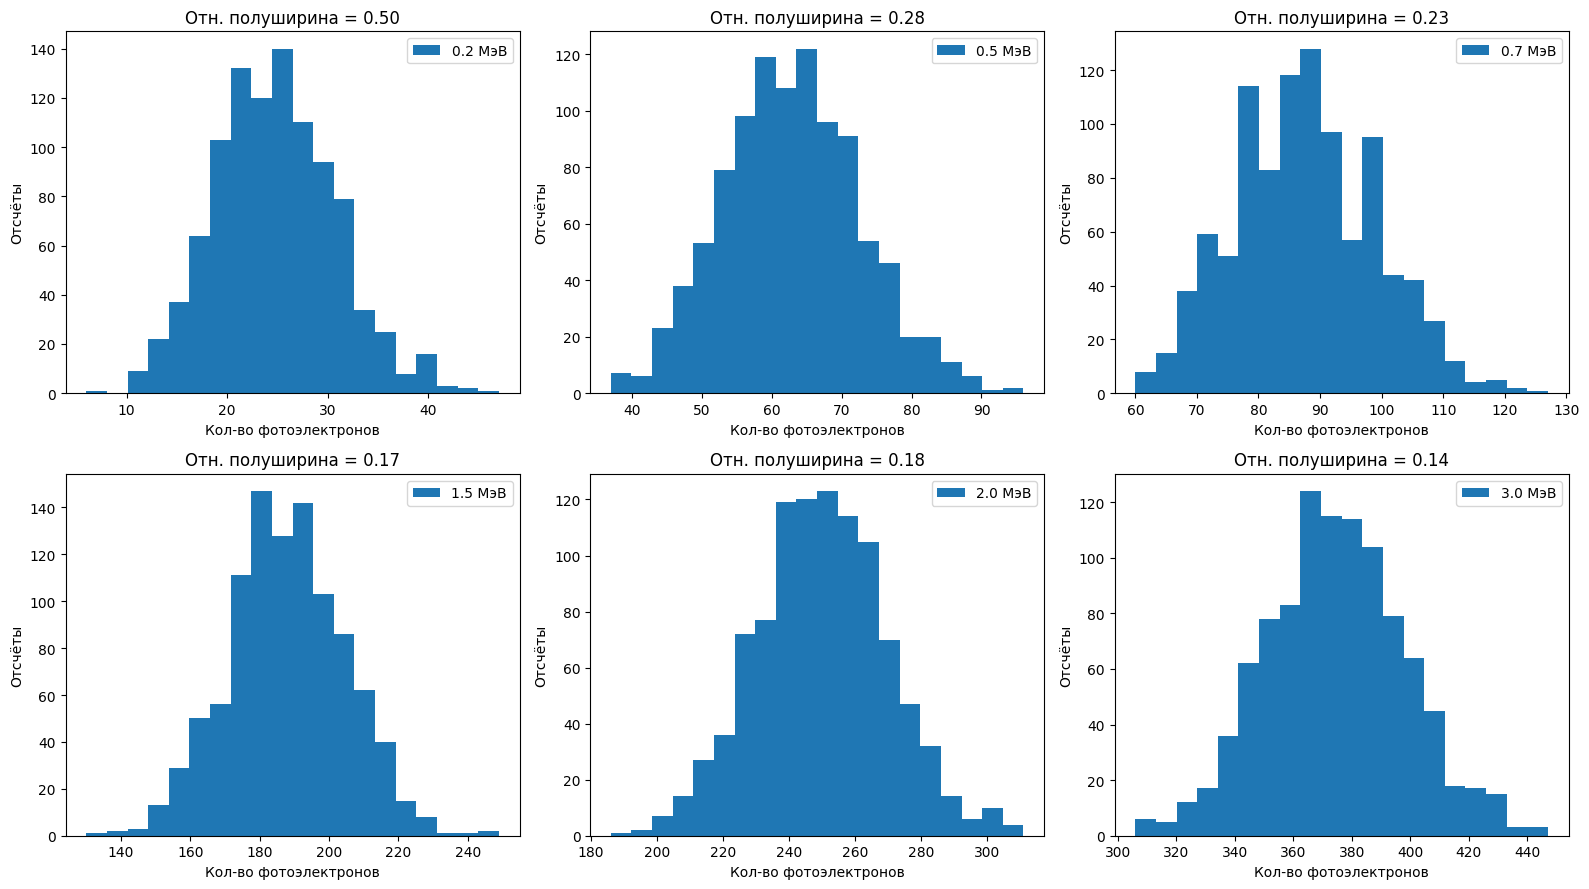

In [25]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))

for i, ax in enumerate(axs.flatten()):

    counts, bins, _ = ax.hist(Charges[i], bins=20, label = f'{Energies[i]} МэВ')
    
    max_bin = bins[counts.argmax()]
    half_inds = np.where(counts>counts.max()/2)[0]
    width = bins[half_inds[-1]] - bins[half_inds[0]]

    ax.set_xlabel('Кол-во фотоэлектронов')
    ax.set_ylabel('Отсчёты')

    ax.set_title(f'Отн. полуширина = {width/max_bin:.2f}')
    
    ax.legend()

plt.tight_layout()

# Видно, что относительная полуширина уменьшается с ростом энергии

In [26]:
x0 = 0*cm
y0 = 0*cm
z0 = 1*m

source_coordinates = np.array([x0, y0, z0])

In [27]:
NewCharges = [deque() for i in range(len(Energies))]

In [28]:
for i, E in enumerate(Energies):
    for _ in range(1000):

        directions = MySource.GeneratePhotonDirections(E)
        EndPoints = MyDet.GeneratePhotonEndPoints(source_coordinates, directions)
        Hits = MyDet.is_PMT(vector=EndPoints)
        Charge = (MyDet.GetPoissoonCounts(Hits)).sum()
        NewCharges[i].append(Charge)

In [29]:
MeanChargesCenter = np.mean(Charges, axis=-1)

In [30]:
MeanChargesMoved = np.mean(NewCharges, axis=-1)

In [31]:
MeanChargesMoved/MeanChargesCenter

array([1.05778834, 1.04250848, 1.04966037, 1.04452685, 1.05105407,
       1.04825881])

# Количество собранного заряда слегка увеличивается. Возможно это связано с тем, что один из фотоумножителей расположен практически на вершине сферы. Сдвигаясь вверх по оси z, мы приближаемся к нему.